In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/spotify_streaming_clean.csv")
df.shape

(50000, 33)

In [3]:
streams_por_anio = (
    df.groupby("release_year")["stream_count"]
    .sum()
    .sort_index()
)

streams_por_anio

release_year
2020     954150849
2021     921810832
2022     922052493
2023    1009133660
2024    1065121362
2025    1046677018
Name: stream_count, dtype: int64

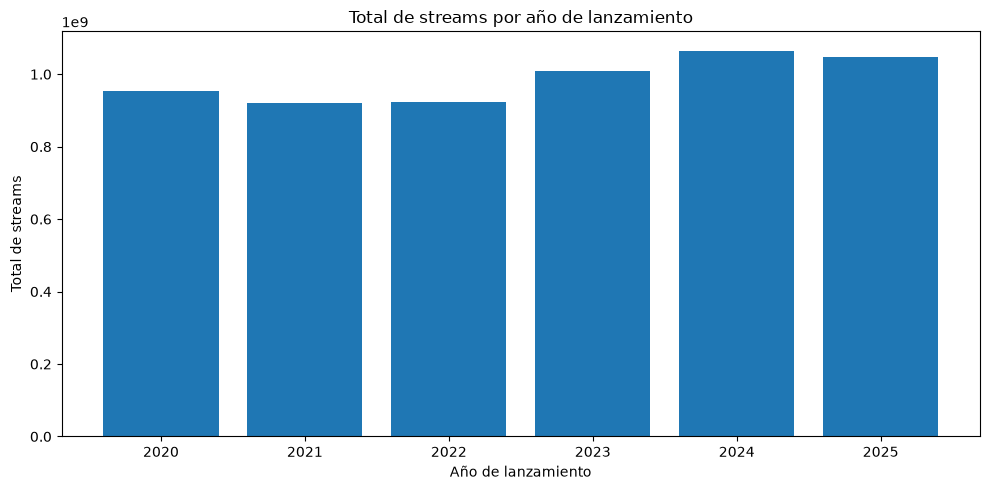

In [4]:
plt.figure(figsize=(10, 5))

plt.bar(
    streams_por_anio.index,
    streams_por_anio.values
)

plt.title("Total de streams por año de lanzamiento")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Total de streams")

plt.tight_layout()
plt.show()

In [5]:
streams_por_genero = (
    df.groupby("genre")["stream_count"]
    .sum()
    .sort_values(ascending=False)
)

streams_por_genero

genre
Pop            1649081624
R&B            1458281734
Hip-Hop         436093929
Latin           340782388
Rock            314706623
EDM             292418495
Folk            227814482
Metal           212286827
Country         168178253
K-Pop           153095403
Indie           131247478
Alternative     129498917
Jazz            105622153
Trap             75303492
Reggaeton        72382728
Punk             44073764
Disco            28737010
Classical        28340064
Afrobeats        27258288
Soul             23742562
Name: stream_count, dtype: int64

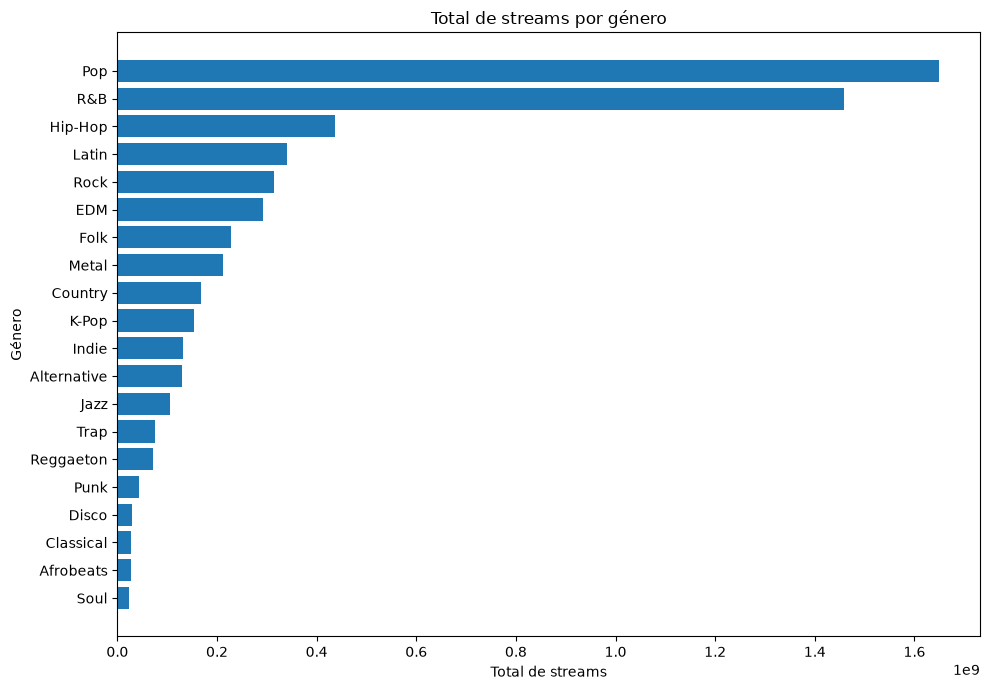

In [6]:
plt.figure(figsize=(10, 7))

plt.barh(
    streams_por_genero.index,
    streams_por_genero.values
)

plt.title("Total de streams por género")
plt.xlabel("Total de streams")
plt.ylabel("Género")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [7]:
promedio_streams_genero = (
    df.groupby("genre")["stream_count"]
    .mean()
    .sort_values(ascending=False)
)

promedio_streams_genero

genre
Alternative    170617.808959
Disco          145136.414141
Rock           132787.604641
Jazz           130397.719753
Country        129967.738022
Latin          128065.534761
Pop            127687.311189
Metal          125242.965782
Indie          123237.068545
Afrobeats      121688.785714
EDM            121486.703365
Punk           114775.427083
Hip-Hop        110965.376336
K-Pop          110618.065751
R&B            109868.284035
Folk           101295.901289
Reggaeton       92207.296815
Trap            82298.898361
Classical       79383.932773
Soul            73054.036923
Name: stream_count, dtype: float64

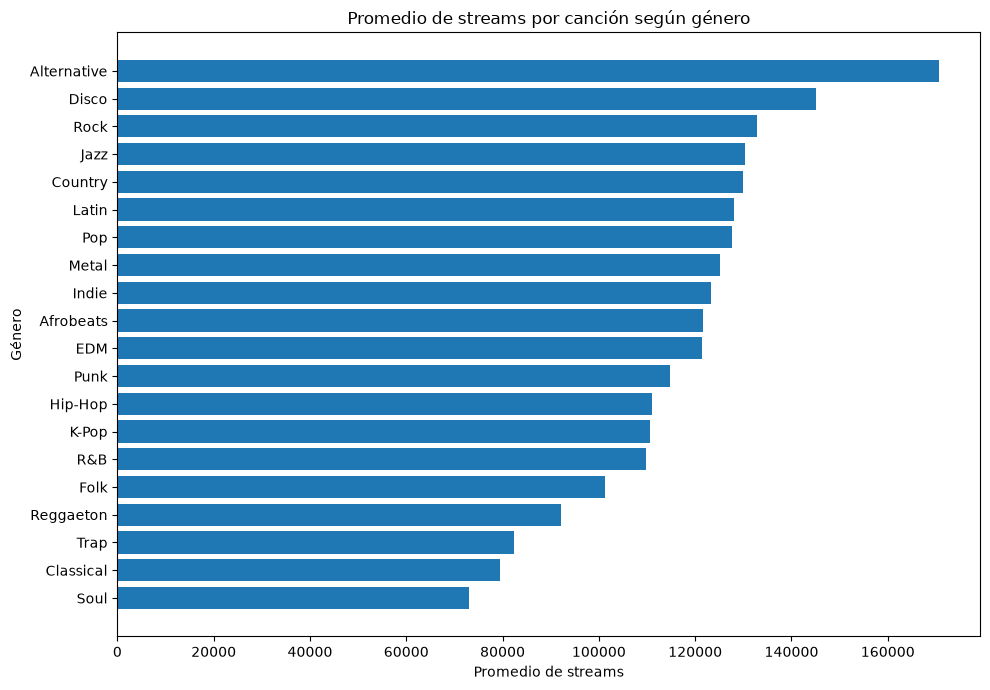

In [8]:
plt.figure(figsize=(10, 7))

plt.barh(
    promedio_streams_genero.index,
    promedio_streams_genero.values
)

plt.title("Promedio de streams por canción según género")
plt.xlabel("Promedio de streams")
plt.ylabel("Género")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [9]:
top_artistas = (
    df.groupby("artist_name")["stream_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_artistas

artist_name
Knot Hart       1303217036
IsleEyre         669929807
Ethereal         433176636
Sterling Zen     245065284
Rocco Ore        219663605
SethStone        179681824
ElaraRain        132996215
ValeGlass        120591894
Frost Nova       104088727
The Dawns         99573871
Name: stream_count, dtype: int64

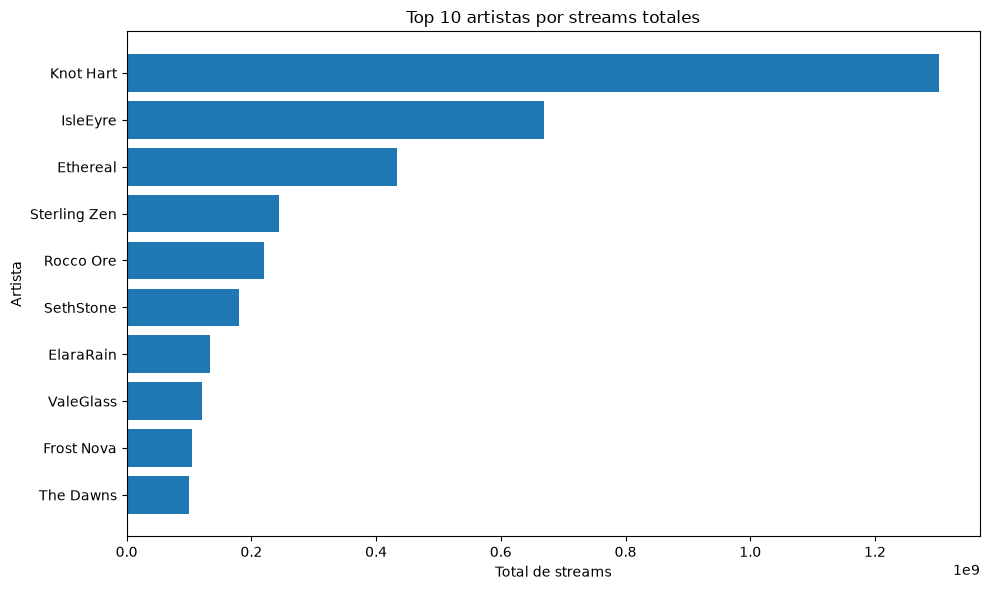

In [10]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_artistas.index,
    top_artistas.values
)

plt.title("Top 10 artistas por streams totales")
plt.xlabel("Total de streams")
plt.ylabel("Artista")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [11]:
artistas_stats = (
    df.groupby("artist_name")["stream_count"]
    .agg(["mean", "count"])
)

top_artistas_promedio = (
    artistas_stats[artistas_stats["count"] >= 20]
    .sort_values("mean", ascending=False)
    .head(10)
)

top_artistas_promedio

,mean,count
artist_name,,
The Inks,711913.434783,23
Dean Fox,614302.700000,20
Prism Hart,576657.500000,58
Grove Nova,425245.338710,124
Dean System,387692.245902,61
Valkyrie,367808.000000,38
Whisper,286372.827586,29
The Glasss,280803.832061,131
SilkHollow,271935.217391,23


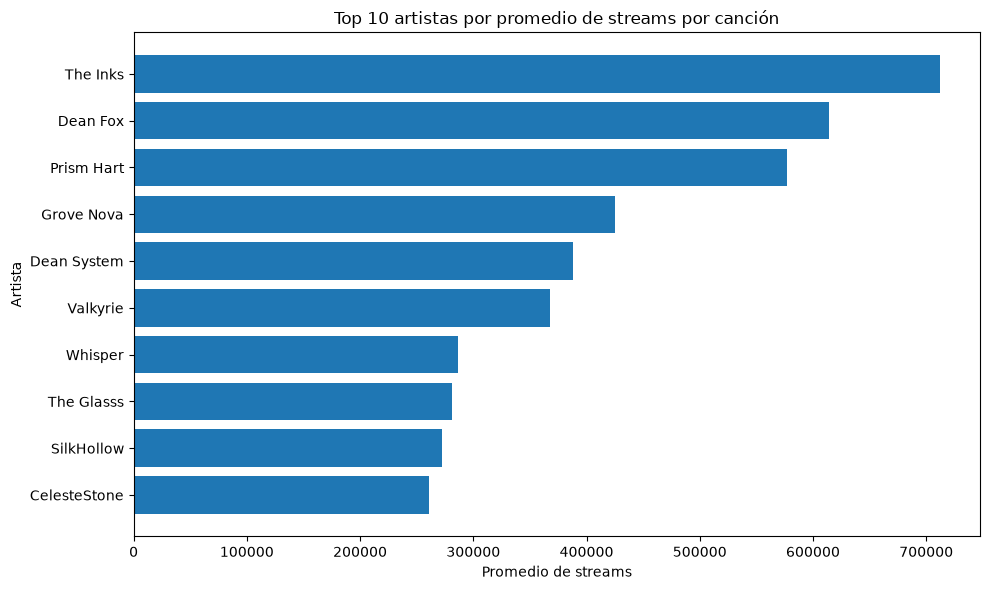

In [12]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_artistas_promedio.index,
    top_artistas_promedio["mean"]
)

plt.title("Top 10 artistas por promedio de streams por canción")
plt.xlabel("Promedio de streams")
plt.ylabel("Artista")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [13]:
streams_por_pais = (
    df.groupby("country")["stream_count"]
    .sum()
    .sort_values(ascending=False)
)

streams_por_pais

country
US    1129891317
GB     465970040
BR     360181160
MX     334310712
IN     301561216
DE     277971272
CA     226527245
FR     201911023
IT     201224437
KR     189697793
ES     188960090
AU     183757445
JP     180478161
NL     135654450
NG     130922731
CL     126136525
SE     124513359
PH     122970976
CO     118083852
PL     109304916
AR     108167109
ID      98405301
ZA      96879290
TR      91609393
EG      87312508
PT      70165764
NZ      69892401
SG      65495856
MY      63163946
TH      57825926
Name: stream_count, dtype: int64

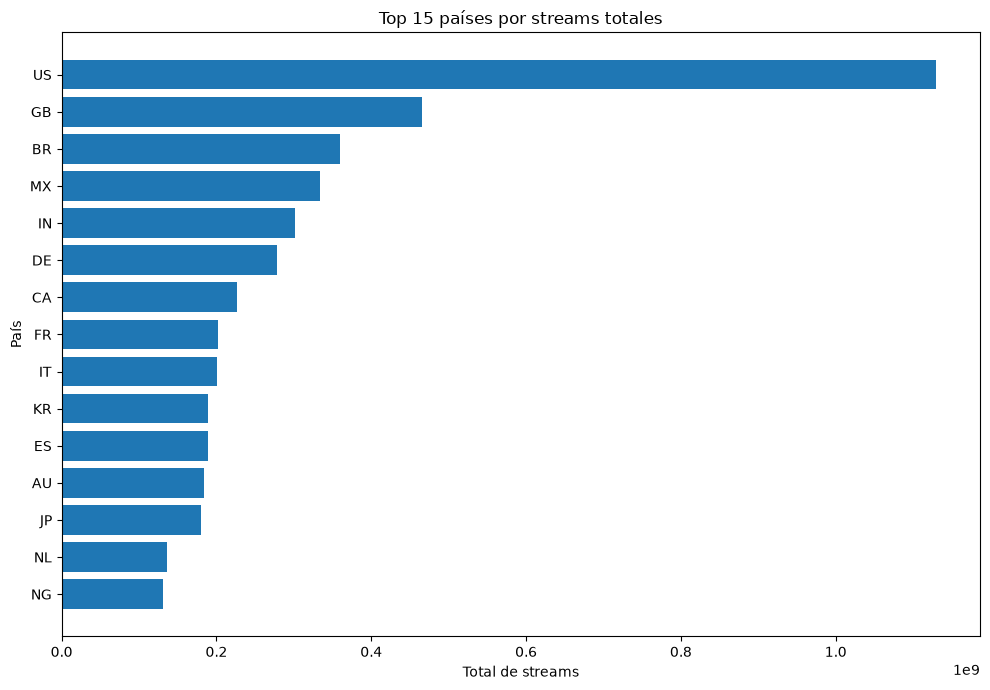

In [14]:
top_paises = streams_por_pais.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_paises.index,
    top_paises.values
)

plt.title("Top 15 países por streams totales")
plt.xlabel("Total de streams")
plt.ylabel("País")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [15]:
promedio_streams_pais = (
    df.groupby("country")["stream_count"]
    .mean()
    .sort_values(ascending=False)
)

promedio_streams_pais

country
EG    168232.192678
NZ    140064.931864
IT    139159.361687
PT    137310.692759
NL    137024.696970
MX    130794.488263
CO    127658.218378
SE    127444.584442
SG    127423.844358
NG    126740.301065
ES    126310.220588
KR    125794.292440
CL    122225.314922
MY    121938.119691
IN    119147.062821
PH    119042.571152
AR    118864.954945
AU    118783.093083
BR    118597.681923
GB    117580.126167
JP    116587.959302
PL    114575.383648
CA    114465.510359
DE    113736.199673
US    113181.540319
TH    110144.620952
FR    101157.827154
ID     99098.993958
ZA     94793.825832
TR     90612.653808
Name: stream_count, dtype: float64

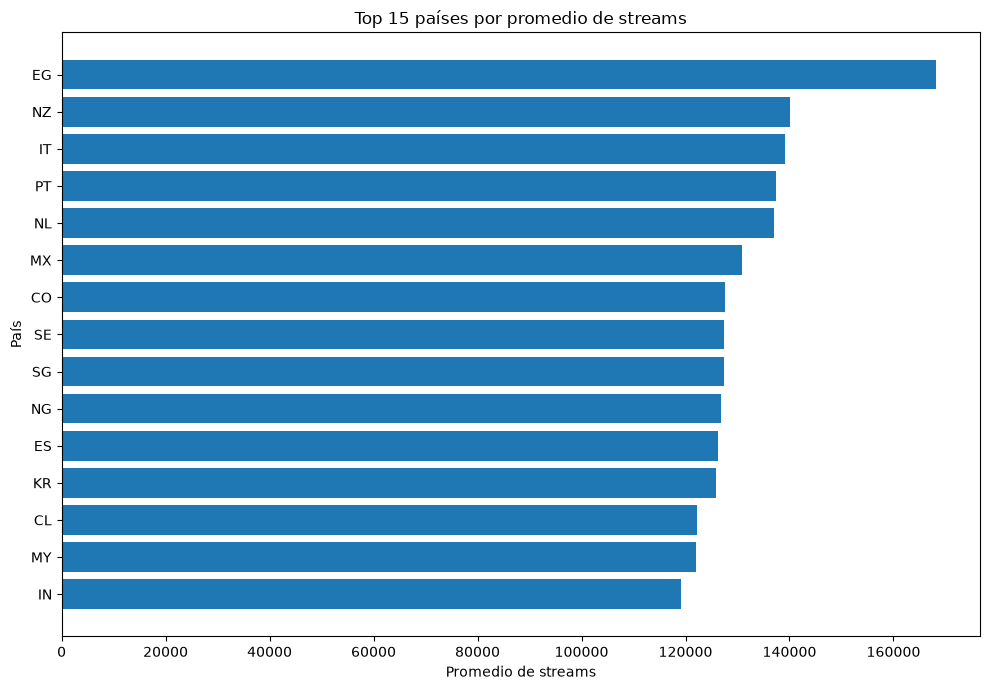

In [16]:
top_promedio_paises = promedio_streams_pais.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_promedio_paises.index,
    top_promedio_paises.values
)

plt.title("Top 15 países por promedio de streams")
plt.xlabel("Promedio de streams")
plt.ylabel("País")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [17]:
columnas_correlacion = [
    "stream_count",
    "popularity",
    "danceability",
    "energy",
    "instrumentalness",
    "tempo",
    "loudness",
    "duration_minutes",
    "upbeat_score"
]

correlaciones = (
    df[columnas_correlacion]
    .corr()["stream_count"]
    .sort_values(ascending=False)
)

correlaciones

stream_count        1.000000
popularity          0.400159
tempo               0.009106
loudness            0.004579
energy              0.004274
upbeat_score        0.003258
instrumentalness    0.002867
duration_minutes   -0.000054
danceability       -0.003071
Name: stream_count, dtype: float64

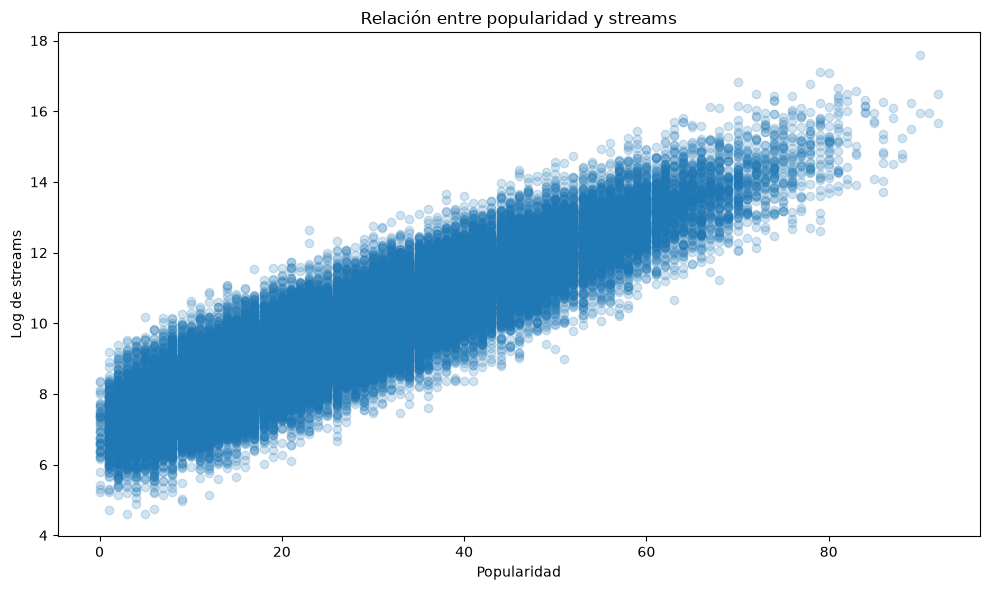

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["popularity"],
    df["log_stream_count"],
    alpha=0.2
)

plt.title("Relación entre popularidad y streams")
plt.xlabel("Popularidad")
plt.ylabel("Log de streams")

plt.tight_layout()
plt.show()

In [19]:
streams_explicit = (
    df.groupby("explicit")["stream_count"]
    .agg(["mean", "median", "count"])
)

streams_explicit

,mean,median,count
explicit,,,
False,119100.495130,16041.0,37576
True,116196.555779,15732.5,12424


In [20]:
df[["popularity", "log_stream_count"]].corr()

,popularity,log_stream_count
popularity,1.000000,0.894075
log_stream_count,0.894075,1.000000


In [21]:
streams_por_dia = (
    df.groupby("release_day_of_week")["stream_count"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

streams_por_dia

,mean,median,count
release_day_of_week,,,
Wednesday,129095.214678,16501.0,7290
Saturday,127372.953725,15257.0,7261
Monday,122734.568585,16092.0,6984
Thursday,120763.005010,16100.0,6986
Sunday,115258.433676,15927.0,7192
Tuesday,110073.188876,15905.0,7174
Friday,103128.748770,15885.0,7113


In [22]:
streams_weekend = (
    df.groupby("is_weekend_release")["stream_count"]
    .agg(["mean", "median", "count"])
)

streams_weekend

,mean,median,count
is_weekend_release,,,
False,117173.110023,16107.0,35547
True,121344.611638,15561.0,14453


In [23]:
streams_popularidad = (
    df.groupby("popularity_category")["stream_count"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

streams_popularidad

,mean,median,count
popularity_category,,,
Very High,4.271218e+06,2788989.0,247
High,6.246320e+05,356208.0,5181
Medium,6.784641e+04,37344.0,21304
Low,7.836398e+03,4783.5,23268


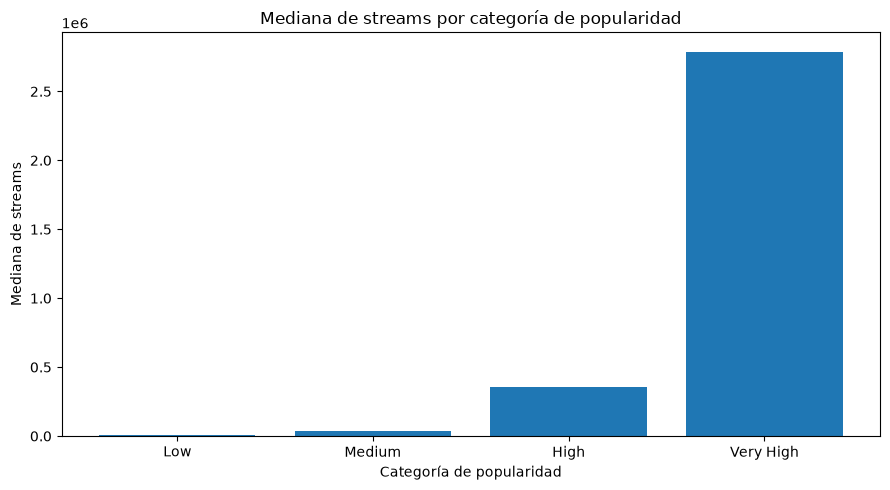

In [24]:
orden = ["Low", "Medium", "High", "Very High"]

mediana_popularidad = (
    df.groupby("popularity_category")["stream_count"]
    .median()
    .reindex(orden)
)

plt.figure(figsize=(9, 5))

plt.bar(
    mediana_popularidad.index,
    mediana_popularidad.values
)

plt.title("Mediana de streams por categoría de popularidad")
plt.xlabel("Categoría de popularidad")
plt.ylabel("Mediana de streams")

plt.tight_layout()
plt.show()

In [25]:
df[["upbeat_score", "stream_count", "log_stream_count"]].corr()

,upbeat_score,stream_count,log_stream_count
upbeat_score,1.000000,0.003258,0.002893
stream_count,0.003258,1.000000,0.432328
log_stream_count,0.002893,0.432328,1.000000


In [26]:
df[["duration_minutes", "stream_count", "log_stream_count"]].corr()

,duration_minutes,stream_count,log_stream_count
duration_minutes,1.000000,-0.000054,0.005972
stream_count,-0.000054,1.000000,0.432328
log_stream_count,0.005972,0.432328,1.000000


In [27]:
df[["tempo", "stream_count", "log_stream_count"]].corr()

,tempo,stream_count,log_stream_count
tempo,1.000000,0.009106,0.000631
stream_count,0.009106,1.000000,0.432328
log_stream_count,0.000631,0.432328,1.000000


In [28]:
df[["loudness", "stream_count", "log_stream_count"]].corr()

,loudness,stream_count,log_stream_count
loudness,1.000000,0.004579,0.002295
stream_count,0.004579,1.000000,0.432328
log_stream_count,0.002295,0.432328,1.000000


In [29]:
df[["instrumentalness", "stream_count", "log_stream_count"]].corr()

,instrumentalness,stream_count,log_stream_count
instrumentalness,1.000000,0.002867,0.004832
stream_count,0.002867,1.000000,0.432328
log_stream_count,0.004832,0.432328,1.000000


In [30]:
streams_mode = (
    df.groupby("mode_name")["stream_count"]
    .agg(["mean", "median", "count"])
)

streams_mode

,mean,median,count
mode_name,,,
Major,120917.830811,15801.0,32514
Minor,113658.004289,16220.5,17486


In [31]:
streams_key = (
    df.groupby("key_name")["stream_count"]
    .agg(["mean", "median", "count"])
    .sort_values("median", ascending=False)
)

streams_key

,mean,median,count
key_name,,,
A,114968.881247,16574.0,4042
C#,126199.794691,16473.0,4257
F#,131730.021101,16411.0,4123
B,133900.422290,16322.0,4253
E,121646.191618,16141.0,4295
C,102757.958745,16100.0,4145
F,118581.124354,15910.0,4061
A#,113459.241200,15674.0,4034
D,111959.332074,15590.5,4234


In [32]:
streams_quarter = (
    df.groupby("release_quarter")["stream_count"]
    .agg(["mean", "median", "count"])
)

streams_quarter

,mean,median,count
release_quarter,,,
Q1,116040.079643,16165.5,12330
Q2,119932.772487,15991.5,12474
Q3,123045.899720,15968.0,12515
Q4,114518.665168,15673.0,12681


In [33]:
streams_month = (
    df.groupby("release_month")["stream_count"]
    .agg(["mean", "median", "count"])
    .sort_index()
)

streams_month

,mean,median,count
release_month,,,
1,117811.533779,15786.0,4337
2,117560.050117,16045.0,3851
3,112772.044182,16842.0,4142
4,139439.304727,16823.0,4125
5,104613.651490,15388.0,4261
6,116217.099560,15915.5,4088
7,120362.820598,15720.0,4214
8,122811.743227,15600.0,4171
9,126020.030993,16362.0,4130


In [34]:
streams_label = (
    df.groupby("label")["stream_count"]
    .agg(["sum", "mean", "median", "count"])
    .sort_values("sum", ascending=False)
)

streams_label.head(15)

,sum,mean,median,count
label,,,,
Columbia Records,410575111,300128.005117,30732.0,1368
RCA Records,386144375,287523.734177,30187.0,1343
Capitol Records,385206157,265476.331496,25934.0,1451
Warner Music Group,367417377,255505.825452,31681.5,1438
Def Jam Recordings,351365659,256471.283942,29891.0,1370
Island Records,342447654,248330.423495,28401.0,1379
Atlantic Records,341345783,246815.461316,29306.0,1383
Republic Records,331750365,238669.327338,28568.0,1390
Sony Music Entertainment,320438110,232369.912980,31885.0,1379


In [35]:
df["label"].value_counts()

label
Catalyst Records            1919
Cipher Music                1919
Wavelength Records          1905
Prism Audio                 1896
Apex Records                1892
Neon Label                  1887
Indie Collective            1882
Horizon Records             1867
Stardust Label              1864
Echo Studios                1851
Independent                 1849
Drift Music                 1838
Midnight Records            1830
Pulse Records               1819
Spectrum Music              1812
Nova Records                1800
Self-Released               1796
Bedroom Records             1778
Capitol Records             1451
Warner Music Group          1438
Epic Records                1405
Republic Records            1390
Atlantic Records            1383
Island Records              1379
Sony Music Entertainment    1379
Def Jam Recordings          1370
Columbia Records            1368
Universal Music Group       1358
RCA Records                 1343
Interscope Records          1332
Name

In [36]:
major_labels = [
    "Columbia Records",
    "RCA Records",
    "Capitol Records",
    "Warner Music Group",
    "Def Jam Recordings",
    "Island Records",
    "Atlantic Records",
    "Republic Records",
    "Sony Music Entertainment",
    "Epic Records",
    "Universal Music Group",
    "Interscope Records"
]

df["label_group"] = np.where(
    df["label"].isin(major_labels),
    "Major",
    "Other"
)

df.groupby("label_group")["stream_count"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
label_group,,,
Major,246219.441191,28832.0,16596
Other,54864.338642,12475.0,33404


In [37]:
df.groupby("label_group")["popularity"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
label_group,,,
Major,33.727705,33.0,16596
Other,25.359119,24.0,33404


In [38]:
label_popularity = (
    df.groupby(["popularity_category", "label_group"])["stream_count"]
    .agg(["mean", "median", "count"])
)

label_popularity

mean     median  count
popularity_category label_group                                
High                Major        7.993862e+05   467385.5   3036
                    Other        3.772874e+05   265661.0   2145
Low                 Major        7.873328e+03     4770.0   5754
                    Other        7.824266e+03     4787.0  17514
Medium              Major        7.395519e+04    41839.0   7559
                    Other        6.448691e+04    34943.0  13745
Very High           Major        4.271218e+06  2788989.0    247

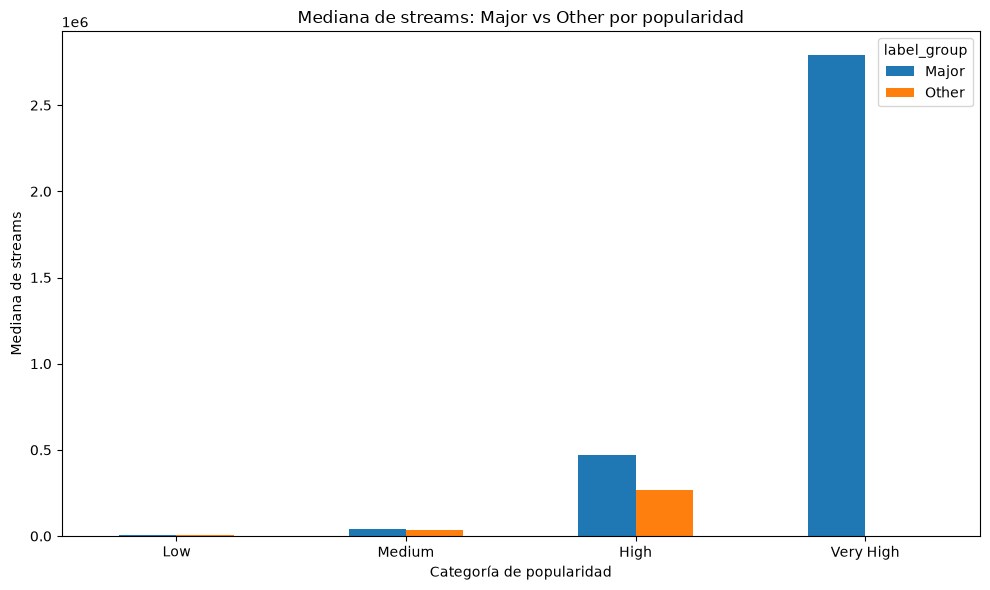

In [39]:
label_popularity_plot = (
    df.groupby(["popularity_category", "label_group"])["stream_count"]
    .median()
    .unstack()
)

orden = ["Low", "Medium", "High", "Very High"]
label_popularity_plot = label_popularity_plot.reindex(orden)

label_popularity_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Mediana de streams: Major vs Other por popularidad")
plt.xlabel("Categoría de popularidad")
plt.ylabel("Mediana de streams")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [40]:
explicit_popularity = (
    df.groupby(["popularity_category", "explicit"])["stream_count"]
    .agg(["mean", "median", "count"])
)

explicit_popularity

mean     median  count
popularity_category explicit                                
High                False     6.350383e+05   360827.5   3892
                    True      5.932110e+05   339411.0   1289
Low                 False     7.816267e+03     4764.0  17392
                    True      7.895984e+03     4850.0   5876
Medium              False     6.786753e+04    37313.0  16099
                    True      6.778108e+04    37642.0   5205
Very High           False     4.016638e+06  2689927.0    193
                    True      5.181107e+06  3673974.5     54

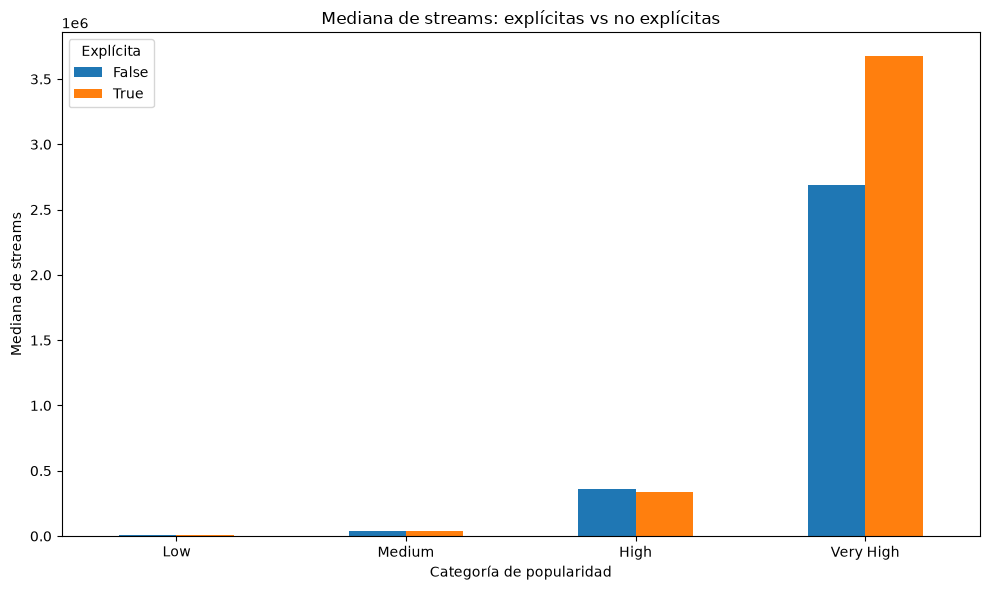

In [41]:
explicit_plot = (
    explicit_popularity["median"]
    .unstack()
    .reindex(["Low", "Medium", "High", "Very High"])
)

explicit_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Mediana de streams: explícitas vs no explícitas")
plt.xlabel("Categoría de popularidad")
plt.ylabel("Mediana de streams")
plt.legend(title="Explícita")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [42]:
correlacion_por_anio = (
    df.groupby("release_year")
    .apply(
        lambda x: x["popularity"].corr(x["log_stream_count"])
    )
)

correlacion_por_anio

release_year
2020    0.896221
2021    0.893193
2022    0.894531
2023    0.895683
2024    0.896354
2025    0.893784
dtype: float64

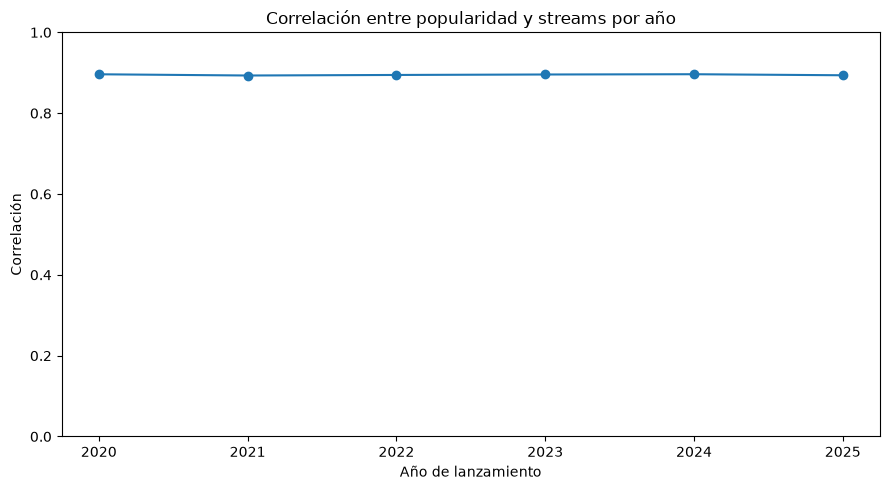

In [43]:
plt.figure(figsize=(9, 5))

correlacion_por_anio.plot(marker="o")

plt.title("Correlación entre popularidad y streams por año")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Correlación")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [44]:
correlacion_por_genero = (
    df.groupby("genre")
    .apply(
        lambda x: x["popularity"].corr(x["log_stream_count"])
    )
    .sort_values(ascending=False)
)

correlacion_por_genero

genre
Disco          0.916962
Afrobeats      0.907457
Jazz           0.903421
Country        0.901999
Metal          0.898265
Pop            0.897433
Hip-Hop        0.896405
Indie          0.895381
EDM            0.894513
Alternative    0.894497
Latin          0.894135
Classical      0.892492
R&B            0.892396
Rock           0.891089
Punk           0.887988
Folk           0.887629
Soul           0.885399
K-Pop          0.883320
Trap           0.876950
Reggaeton      0.876197
dtype: float64

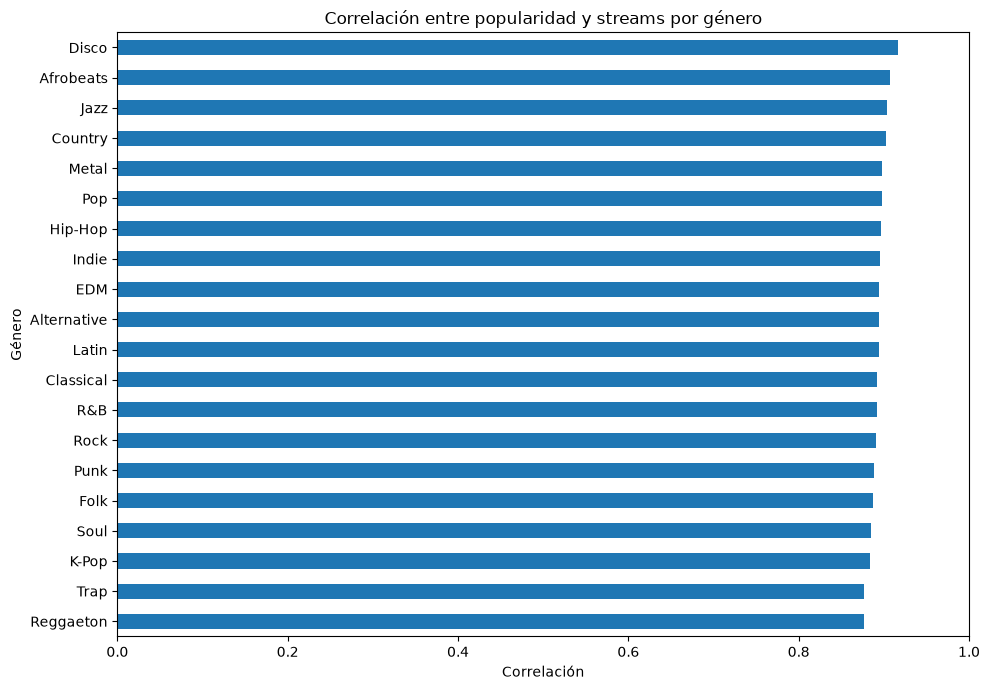

In [45]:
plt.figure(figsize=(10, 7))

correlacion_por_genero.sort_values().plot(kind="barh")

plt.title("Correlación entre popularidad y streams por género")
plt.xlabel("Correlación")
plt.ylabel("Género")

plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
## Conclusiones del análisis exploratorio

- La popularidad presenta una relación fuerte con el número de streams. La correlación entre `popularity` y `log_stream_count` es aproximadamente 0.89.
- Esta relación se mantiene estable entre 2020 y 2025 y también entre los diferentes géneros musicales.
- Pop y R&B concentran el mayor volumen total de streams, aunque esto no significa necesariamente que tengan el mayor promedio de streams por canción.
- Estados Unidos concentra el mayor volumen total de streams del dataset.
- Las características musicales analizadas, como tempo, energía, danceability, instrumentalness, loudness, duración y upbeat score, presentan correlaciones muy débiles con los streams.
- El contenido explícito no muestra una ventaja consistente en streams frente al contenido no explícito.
- Los lanzamientos asociados a sellos clasificados como Major presentan, en general, mayores niveles de popularidad y streams que el grupo Other.
- El día, mes y trimestre de lanzamiento muestran diferencias en los resultados, pero no una relación tan marcada como la popularidad.
- Los resultados muestran que popularidad, sello discográfico, género, artista y mercado son dimensiones más relevantes para continuar el análisis en SQL, Excel y Power BI.